In [3]:
!pip install langchain-community langchain-text-splitters langchain-core langchain-huggingface langgraph faiss-cpu pypdf python-dotenv

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
!pip install langchain-community langchain-text-splitters pypdf

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
from typing import List, TypedDict
import re
import time

from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_huggingface import HuggingFaceEmbeddings, ChatHuggingFace
from langchain_community.vectorstores import FAISS
from langchain_core.prompts import ChatPromptTemplate
from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from typing import Literal
from pydantic import BaseModel,Field

load_dotenv()

C:\Users\gwek2\AppData\Local\Temp\ipykernel_24336\3407949589.py:5: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


True

In [8]:
import os
os.environ["OPENAI_API_KEY"] = "My api key"

In [4]:
pdf_urls = [
    "https://github.com/janishar/mit-deep-learning-book-pdf/raw/master/complete-book-pdf/deeplearningbook.pdf",
    "https://www.cs.cmu.edu/~tom/files/MachineLearningTomMitchell.pdf",
]

docs = []
for url in pdf_urls:
    docs += PyPDFLoader(url).load()

print(f"Loaded {len(docs)} pages total")

Loaded 1221 pages total


In [5]:
splitter = RecursiveCharacterTextSplitter(chunk_size=600, chunk_overlap=150)
chunks = splitter.split_documents(docs)
print(f"Created {len(chunks)} chunks")

Created 6172 chunks


In [9]:
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")
vector_store = FAISS.from_documents(chunks, embeddings)
vector_store.save_local("faiss_index")  # so you don't re-embed next time

In [10]:
retriever = vector_store.as_retriever(search_kwargs={"k": 4})

In [11]:
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

In [12]:
results = retriever.invoke("What is backpropagation?")
for r in results:
    print(r.page_content[:200], "\n---")

Theback-propagationalgorithm( , ),oftensimplycalledRumelhart et al. 1986a
backprop,allowstheinformationfromthecosttothenﬂowbackwardsthrough
thenetwork,inordertocomputethegradient.
Computingananalytica 
---
CHAPTER6. DEEPFEEDFORWARDNETWORKS
back-propagationavoidsrepeatingmanycommonsubexpressions. Thistable-ﬁlling
strategyissometimescalled .dynamicprogramming
6.5.7 Example: Back-Propagation for MLP Traini 
---
In order to develop a better intuition for the operation of BACKPROPAGATION 
in this example, let us examine the operation of the gradient descent procedure in 
---
The learning problem faced by BACKPROPAGATION is to search a large hypoth- 
esis space defined by all possible weight values for all the units in the network. 
The situation can be visualized in terms 
---


In [13]:
from typing import TypedDict, List, Literal
from langchain_core.documents import Document

class State(TypedDict):
    question: str
    need_retrieval: bool
    docs: List[Document]
    is_relevant: bool
    answer: str
    is_supported: bool

In [14]:
class RetrieveDecision(BaseModel):
    should_retrieve: bool = Field(
        ...,
        description="True if external documents are needed to answer reliably, else False."
    )

decide_retrieval_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You decide whether retrieval is needed.\n"
            "Return JSON that matches this schema:\n"
            "{{'should_retrieve': boolean}}\n\n"
            "Guidelines:\n"
            "- should_retrieve=True if answering requires specific facts, citations, or info likely not in the model.\n"
            "- should_retrieve=False for general explanations, definitions, or reasoning that doesn't need sources.\n"
            "- If unsure, choose True."
        ),
        ("human", "Question: {question}"),
    ]
)

should_retrieve_llm = llm.with_structured_output(RetrieveDecision)

def decide_retrieval(state: State):
    decision: RetrieveDecision = should_retrieve_llm.invoke(
        decide_retrieval_prompt.format_messages(question=state["question"])
    )
    return {"need_retrieval": decision.should_retrieve}

In [15]:
direct_generation_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "Answer the question using only your general knowledge.\n"
            "Do NOT assume access to external documents.\n"
            "If you are unsure or the answer requires specific sources, say:\n"
            "'I don't know based on my general knowledge.'"
        ),
        ("human", "{question}"),  # fixed typo
    ]
)

def generate_direct(state: State):
    out = llm.invoke(
        direct_generation_prompt.format_messages(
            question=state["question"]
        )
    )
    return {"answer": out.content}

In [16]:
# test decide_retrieval
print(decide_retrieval({"question": "What is the capital of France?"}))
print(decide_retrieval({"question": "What is NexaAI's pricing for the Enterprise plan?"}))

# test generate_direct
print(generate_direct({"question": "What is the capital of France?"}))

{'need_retrieval': False}
{'need_retrieval': True}
{'answer': 'The capital of France is Paris.'}


In [18]:
# --- is_relevant ---

class RelevanceDecision(BaseModel):
    is_relevant: bool = Field(
        ...,
        description="True if the retrieved documents contain enough information to answer the question."
    )

is_relevant_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You judge whether retrieved documents are relevant and sufficient to answer the question.\n"
     "Return JSON matching: {{'is_relevant': boolean}}\n\n"
     "Guidelines:\n"
     "- True if the documents directly address the question with enough detail.\n"
     "- False if the documents are off-topic, too vague, or insufficient.\n"
     "If unsure, choose False (triggers fallback)."
    ),
    ("human", "Question: {question}\n\nDocuments:\n{docs}"),
])

is_relevant_llm = llm.with_structured_output(RelevanceDecision)

def is_relevant(state: State):
    docs_text = "\n\n".join(d.page_content for d in state["docs"])
    decision = is_relevant_llm.invoke(
        is_relevant_prompt.format_messages(question=state["question"], docs=docs_text)
    )
    return {"is_relevant": decision.is_relevant}


# --- generate_from_context ---

generate_from_context_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "Answer the question using ONLY the provided context.\n"
     "If the context doesn't contain enough information, say so honestly.\n"
     "Cite specific details from the context where relevant."
    ),
    ("human", "Question: {question}\n\nContext:\n{docs}"),
])

def generate_from_context(state: State):
    docs_text = "\n\n".join(d.page_content for d in state["docs"])
    out = llm.invoke(
        generate_from_context_prompt.format_messages(
            question=state["question"], docs=docs_text
        )
    )
    return {"answer": out.content}

In [19]:
test_state = {
    "question" : "what os back propagation",
    "docs" : retriever.invoke("what is back propagation"),
}

print(is_relevant(test_state))
print(generate_from_context(test_state))

{'is_relevant': True}
{'answer': 'Back propagation is a method used in training multilayer perceptrons (MLPs) to compute the gradient of the cost function with respect to the network weights. It employs a strategy that allows information from the cost to flow backward through the network, enabling the iterative reduction of error in the network\'s fit to the training examples using gradient descent. This process helps in searching the hypothesis space by adjusting the weights to minimize the training error. While the term "back-propagation" is often used to refer to the entire learning algorithm for multi-layer neural networks, it specifically denotes the method for calculating the gradient efficiently, rather than the overall learning process.'}


In [22]:
# --- is_sup ---
class SupportDecision(BaseModel):
    is_supported: bool = Field(
        ...,
        description="True if the answer is factually grounded in the provided documents, else False."
    )

is_sup_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You check whether an answer is fully supported by the given documents.\n"
     "Return JSON matching: {{'is_supported': boolean}}\n\n"
     "- True only if every claim in the answer is backed by the documents.\n"
     "- False if the answer contains unsupported claims or hallucinations."
    ),
    ("human", "Documents:\n{docs}\n\nAnswer:\n{answer}"),
])

is_sup_llm = llm.with_structured_output(SupportDecision)

def is_sup(state: State):
    docs_text = "\n\n".join(d.page_content for d in state["docs"])
    decision = is_sup_llm.invoke(
        is_sup_prompt.format_messages(docs=docs_text, answer=state["answer"])
    )
    return {"is_supported": decision.is_supported}


# --- no_answer_found ---
def no_answer_found(state: State):
    return {"answer": "I couldn't find relevant information to answer this question."}

In [23]:
test_state = {
    "docs": retriever.invoke("What is backpropagation?"),
    "answer": "Back propagation is a method used in training multilayer perceptrons (MLPs) to compute the gradient..."
}
print(is_sup(test_state))

{'is_supported': True}


In [24]:
class State(TypedDict):
    question: str
    need_retrieval: bool
    docs: List[Document]
    is_relevant: bool
    answer: str
    is_supported: bool

In [28]:
def route_after_decide(state: State) -> Literal["generate_direct", "retrieve"]:
    if state["need_retrieval"]:
        return "retrieve"
    return "generate_direct"

In [26]:
def retrieve(state: State):
    return {"docs": retriever.invoke(state["question"])}

In [29]:
for name in ["decide_retrieval", "retrieve", "is_relevant", "generate_from_context", 
             "generate_direct", "is_sup", "no_answer_found", "route_after_decide"]:
    print(name, "->", name in dir())

decide_retrieval -> True
retrieve -> True
is_relevant -> True
generate_from_context -> True
generate_direct -> True
is_sup -> True
no_answer_found -> True
route_after_decide -> True


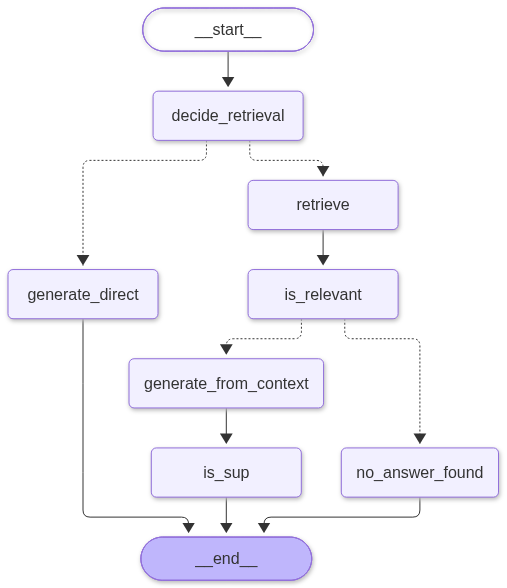

In [30]:
from langgraph.graph import StateGraph, START, END

g = StateGraph(State)

# --------------------
# Nodes
# --------------------
g.add_node("decide_retrieval", decide_retrieval)
g.add_node("retrieve", retrieve)
g.add_node("is_relevant", is_relevant)
g.add_node("generate_from_context", generate_from_context)
g.add_node("generate_direct", generate_direct)
g.add_node("is_sup", is_sup)
g.add_node("no_answer_found", no_answer_found)

# --------------------
# Edges
# --------------------
g.add_edge(START, "decide_retrieval")

g.add_conditional_edges(
    "decide_retrieval",
    route_after_decide,
    {
        "generate_direct": "generate_direct",
        "retrieve": "retrieve",
    },
)

g.add_edge("retrieve", "is_relevant")

g.add_conditional_edges(
    "is_relevant",
    lambda state: "generate_from_context" if state["is_relevant"] else "no_answer_found",
    {
        "generate_from_context": "generate_from_context",
        "no_answer_found": "no_answer_found",
    },
)

g.add_edge("generate_from_context", "is_sup")
g.add_edge("generate_direct", END)
g.add_edge("is_sup", END)
g.add_edge("no_answer_found", END)

app = g.compile()
app

In [31]:
## testing 
result = app.invoke({
    "question": "What is backpropagation?",
    "need_retrieval": False,   # initial placeholder — decide_retrieval will override this
    "docs": [],
    "is_relevant": False,
    "answer": "",
    "is_supported": False,
})

print(result)
print("\n--- Final Answer ---")
print(result["answer"])

{'question': 'What is backpropagation?', 'need_retrieval': False, 'docs': [], 'is_relevant': False, 'answer': 'Backpropagation is an algorithm used in artificial neural networks to train models by minimizing the error between the predicted output and the actual output. It works by calculating the gradient of the loss function with respect to each weight in the network, allowing the model to update its weights in the direction that reduces the error.\n\nThe process involves two main steps:\n\n1. **Forward Pass**: The input data is passed through the network, layer by layer, to compute the output. The loss (or error) is then calculated by comparing the predicted output to the actual target values.\n\n2. **Backward Pass**: The algorithm then computes the gradients of the loss with respect to each weight by applying the chain rule of calculus. This involves propagating the error backward through the network, starting from the output layer and moving towards the input layer. The weights are

In [32]:
result2 = app.invoke({
    "question": "What is NexaAI's pricing for the Growth plan?",
    "need_retrieval": False,
    "docs": [],
    "is_relevant": False,
    "answer": "",
    "is_supported": False,
})
print(result2["answer"])

I couldn't find relevant information to answer this question.


In [33]:
result3 = app.invoke({
    "question": "What is 2 + 2?",
    "need_retrieval": False,
    "docs": [],
    "is_relevant": False,
    "answer": "",
    "is_supported": False,
})
print(result3["answer"])

2 + 2 equals 4.


In [36]:
## forgot to add the companies policies docs
## testing by aading new docs 

new_pdf_paths = [
    "Company_Profile.pdf",
    "Product_and_Pricing.pdf",
    "Company_Policies.pdf",
]

new_docs = []
for path in new_pdf_paths:
    new_docs += PyPDFLoader(path).load()

print(f"Loaded {len(new_docs)} new pages")

new_chunks = splitter.split_documents(new_docs)  # reuse the same splitter you already defined

vector_store.add_documents(new_chunks)
vector_store.save_local("faiss_index")  # persist so you don't lose this merge

Loaded 8 new pages


In [37]:
result2 = app.invoke({
    "question": "What is NexaAI's pricing for the Growth plan?",
    "need_retrieval": False,
    "docs": [],
    "is_relevant": False,
    "answer": "",
    "is_supported": False,
})
print(result2["answer"])

NexaAI's pricing for the Growth plan is ₹5,999 per user per month. This plan includes access to NexaChat, NexaInsight, and NexaSupport, along with advanced analytics and reporting, third-party integrations, and priority email and chat support.
